In [12]:
from pathlib import Path
import xarray as xr
import pandas as pd
from neuralhydrology.evaluation.metrics import (
    mean_peak_timing,
    missed_peaks,
    mean_absolute_percentage_peak_error,
)
import matplotlib.pyplot as plt
from xarray import DataArray
import numpy as np

from scipy import signal
from neuralhydrology.datautils import utils
from neuralhydrology.evaluation.metrics import _validate_inputs, _mask_valid

In [13]:
# ------------- Paths -------------
time_series = Path("/inputs/data_updated_2/time_series") #US
basins_file = Path("/home/azureuser/NeuralHydrologyAzure/2_final_runs/1_531_caravan_vs_camels/2_531_basin.txt") #US
us_output = Path("./peak_metrics/530_united_states") #US
us_output.mkdir(parents=True, exist_ok=True)

#127 basins
# ------------- Paths -------------
time_series_127 = Path("../../1_preparing_data/2_us_127_basins/data/time_series") #US
basins_file_127 = Path("../../1_preparing_data/2_us_127_basins/basins_subset_test.txt") #US
us_output_127 = Path("./peak_metrics/united_states") #US
us_output_127.mkdir(parents=True, exist_ok=True)

In [14]:
def custom_mean_peak_timing(obs, sim, window=None, resolution='1D', datetime_coord=None, distance=100):
    _validate_inputs(obs, sim)
    obs, sim = _mask_valid(obs, sim)

    peaks, _ = signal.find_peaks(obs.values, distance=distance, prominence=np.std(obs.values))

    if datetime_coord is None:
        datetime_coord = utils.infer_datetime_coord(obs)
    if window is None:
        window = max(int(utils.get_frequency_factor('12h', resolution)), 3)

    timing_errors = []
    for idx in peaks:
        if (idx - window < 0) or (idx + window >= len(obs)) or (
            pd.date_range(obs[idx - window][datetime_coord].values,
                          obs[idx + window][datetime_coord].values,
                          freq=resolution).size != 2 * window + 1):
            continue

        if (sim[idx] > sim[idx - 1]) and (sim[idx] > sim[idx + 1]):
            peak_sim = sim[idx]
        else:
            values = sim[idx - window:idx + window + 1]
            peak_sim = values[values.argmax()]

        peak_obs = obs[idx]
        delta = peak_obs.coords[datetime_coord] - peak_sim.coords[datetime_coord]
        timing_errors.append(np.abs(delta.values / pd.to_timedelta(resolution)))

    return np.mean(timing_errors) if len(timing_errors) > 0 else np.nan


def custom_missed_peaks(obs, sim, window=None, resolution='1D', percentile=80, datetime_coord=None, distance=30):
    _validate_inputs(obs, sim)
    obs, sim = _mask_valid(obs, sim)

    min_obs_height = np.percentile(obs.values, percentile)
    min_sim_height = np.percentile(sim.values, percentile)

    peaks_obs_times, _ = signal.find_peaks(obs, distance=distance, height=min_obs_height)
    peaks_sim_times, _ = signal.find_peaks(sim, distance=distance, height=min_sim_height)

    if len(peaks_obs_times) == 0:
        return 0.

    if datetime_coord is None:
        datetime_coord = utils.infer_datetime_coord(obs)
    if window is None:
        window = max(int(utils.get_frequency_factor('12h', resolution)), 1)

    missed_events = 0
    for idx in peaks_obs_times:
        if (idx - window < 0) or (idx + window >= len(obs)) or (
            pd.date_range(obs[idx - window][datetime_coord].values,
                          obs[idx + window][datetime_coord].values,
                          freq=resolution).size != 2 * window + 1):
            continue

        nearby_peak_sim_index = np.where(np.abs(peaks_sim_times - idx) <= window)[0]
        if len(nearby_peak_sim_index) == 0:
            missed_events += 1

    return missed_events / len(peaks_obs_times)

# def mean_absolute_percentage_peak_error(obs: DataArray, sim: DataArray) -> float:
#     r"""Calculate the mean absolute percentage error (MAPE) for peaks

#     .. math:: \text{MAPE}_\text{peak} = \frac{1}{P}\sum_{p=1}^{P} \left |\frac{Q_{s,p} - Q_{o,p}}{Q_{o,p}} \right | \times 100,

#     where :math:`Q_{s,p}` are the simulated peaks (here, `sim`), :math:`Q_{o,p}` the observed peaks (here, `obs`) and
#     `P` is the number of peaks.

#     Uses scipy.find_peaks to find peaks in the observed time series. The observed peaks indices are used to subset
#     observed and simulated flows. Finally, the MAPE metric is calculated as the mean absolute percentage error
#     of observed peak flows and corresponding simulated flows.

#     Parameters
#     ----------
#     obs : DataArray
#         Observed time series.
#     sim : DataArray
#         Simulated time series.

#     Returns
#     -------
#     float
#         Mean absolute percentage error (MAPE) for peaks.
#     """
#     # verify inputs
#     _validate_inputs(obs, sim)

#     # get time series with only valid observations
#     obs, sim = _mask_valid(obs, sim)

#     # return np.nan if there are no valid observed or simulated values
#     if obs.size == 0 or sim.size == 0:
#         return np.nan

#     # heuristic to get indices of peaks and their corresponding height.
#     peaks, _ = signal.find_peaks(obs.values, distance=100, prominence=np.std(obs.values))

#     # check if any peaks exist, otherwise return np.nan
#     if peaks.size == 0:
#         return np.nan

#     # subset data to only peak values
#     obs = obs[peaks].values
#     sim = sim[peaks].values

#     # calculate the mean absolute percentage peak error
#     peak_mape = np.sum(np.abs((sim - obs) / obs)) / peaks.size * 100

#     return peak_mape

# US

In [15]:
with open(basins_file, "r") as f:
    basins = f.read().splitlines()

len(basins)

531

In [16]:
ds = xr.open_dataset(time_series / "camels_01022500.nc")
ds

<xarray.Dataset> Size: 5MB
Dimensions:                                        (date: 26662)
Coordinates:
  * date                                           (date) datetime64[ns] 213kB ...
Data variables: (12/41)
    dewpoint_temperature_2m_max                    (date) float32 107kB ...
    dewpoint_temperature_2m_mean                   (date) float32 107kB ...
    dewpoint_temperature_2m_min                    (date) float32 107kB ...
    potential_evaporation_sum_ERA5_LAND            (date) float32 107kB ...
    potential_evaporation_sum_FAO_PENMAN_MONTEITH  (date) float32 107kB ...
    snow_depth_water_equivalent_max                (date) float32 107kB ...
    ...                                             ...
    volumetric_soil_water_layer_3_mean             (date) float32 107kB ...
    volumetric_soil_water_layer_3_min              (date) float32 107kB ...
    volumetric_soil_water_layer_4_max              (date) float32 107kB ...
    volumetric_soil_water_layer_4_mean             (date) float32 107kB ...
    volumetric_soil_water_layer_4_min              (date) float32 107kB ...
    camels_precipitation                           (date) float64 213kB ...
Attributes:
    Units:     dewpoint_temperature_2m: Dew point temperature [°C]\npotential...
    Timezone:  America/New_York
    Sources:   All forcing and state variables are derived from ERA5-Land hou...

In [17]:
# Date range filter
DATE_START = "1989-10-01"
DATE_END   = "2014-09-30"

In [18]:
PRECIP_COLS_US = {
    "camels": "camels_precipitation",
    # "CARAVAN":   "total_precipitation_sum",
    # "CHIRPS":   "chirps_precipitation",
    # "MSWEP":    "mswep_precipitation",
}
GAUGE_COL_US = "streamflow" #"camels_precipitation"

results_us = []

for basin_name in basins:
    basin_id = basin_name #.replace("camels_", "")

    try:
        ds = xr.open_dataset(time_series / f"{basin_name}.nc")
        # ds = ds.drop_vars("basin")

        ds = ds.sel(date=slice(DATE_START, DATE_END))

        # obs: DataArray = ds[GAUGE_COL_US]
        obs: DataArray = ds[GAUGE_COL_US]

        for product_name, col in PRECIP_COLS_US.items():
            if col not in ds:
                print(f"  Skipping {product_name} for {basin_id}: column not found")
                continue

            sim: DataArray = ds[col]
            row = {"basin": basin_id, "product": product_name}

            try:
                row["peak_timing"] = custom_mean_peak_timing(
                    obs, sim, resolution="1D", datetime_coord="date",
                    distance=100, window=5
                )
            except Exception as e:
                row["peak_timing"] = np.nan
                print(f"  peak_timing failed ({basin_id}, {product_name}): {e}")

            try:
                row["missed_peaks"] = custom_missed_peaks(
                    obs, sim, resolution="1D", datetime_coord="date",
                    distance=100, window=5
                )
            except Exception as e:
                row["missed_peaks"] = np.nan
                print(f"  missed_peaks failed ({basin_id}, {product_name}): {e}")

            # try:
            #     row["mape_peak"] = mean_absolute_percentage_peak_error(obs, sim)
            # except Exception as e:
            #     row["mape_peak"] = np.nan
            #     print(f"  mape_peak failed ({basin_id}, {product_name}): {e}")

            results_us.append(row)

    except StopIteration:
        print(f"Skipping {basin_id}: CAMELS txt file not found")
    except Exception as e:
        print(f"Skipping {basin_id}: {e}")

# ── Summary ───────────────────────────────────────────────────────────────────
df_results_us = pd.DataFrame(results_us)

In [19]:
df_results_us.to_csv(us_output / "peak_metrics.csv", index=False)

## Trying different window sizes

What I want to do is to explore how the metrics change with the size of the window. Then, when it does not change anymore, I'll do the plots in the exploring_snow_nse_relationship tho see hwo big is this lag depending on the fraction of now. If larger fraction of snow have bigger lags, then the timing of precipitation is not that important (compared to reality), compared to the rain dominated basins.

In [21]:
PRECIP_COLS_US = {
    "camels": "camels_precipitation",
    # "CARAVAN":   "total_precipitation_sum",
    # "CHIRPS":   "chirps_precipitation",
    # "MSWEP":    "mswep_precipitation",
}
GAUGE_COL_US = "streamflow"

WINDOW_SIZES = [5, 15, 30, 60, 90]

results_us = []

for basin_name in basins:
    basin_id = basin_name

    try:
        ds = xr.open_dataset(time_series / f"{basin_name}.nc")
        ds = ds.sel(date=slice(DATE_START, DATE_END))

        obs: DataArray = ds[GAUGE_COL_US]

        for product_name, col in PRECIP_COLS_US.items():
            if col not in ds:
                print(f"  Skipping {product_name} for {basin_id}: column not found")
                continue

            sim: DataArray = ds[col]

            for window in WINDOW_SIZES:
                row = {"basin": basin_id, "product": product_name, "window": window}

                try:
                    row["peak_timing"] = custom_mean_peak_timing(
                        obs, sim, resolution="1D", datetime_coord="date",
                        distance=100, window=window
                    )
                except Exception as e:
                    row["peak_timing"] = np.nan
                    print(f"  peak_timing failed ({basin_id}, {product_name}, window={window}): {e}")

                # try:
                #     row["missed_peaks"] = custom_missed_peaks(
                #         obs, sim, resolution="1D", datetime_coord="date",
                #         distance=100, window=window
                #     )
                # except Exception as e:
                #     row["missed_peaks"] = np.nan
                #     print(f"  missed_peaks failed ({basin_id}, {product_name}, window={window}): {e}")

                results_us.append(row)

    except StopIteration:
        print(f"Skipping {basin_id}: CAMELS txt file not found")
    except Exception as e:
        print(f"Skipping {basin_id}: {e}")

# ── Summary ───────────────────────────────────────────────────────────────────
df_results_us = pd.DataFrame(results_us)

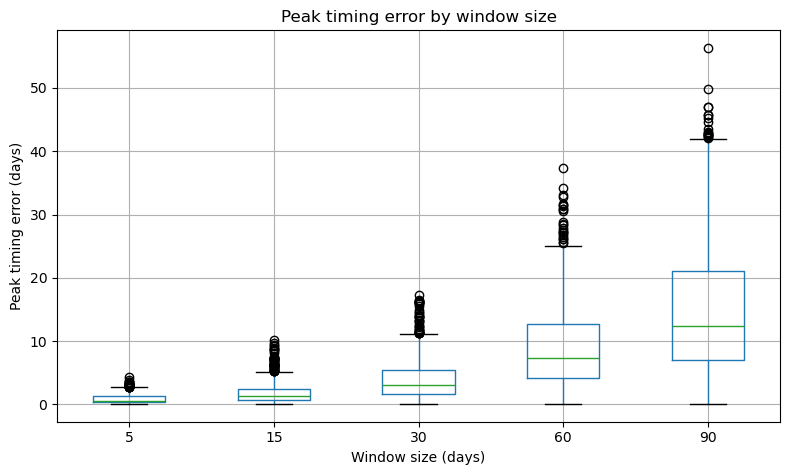

In [22]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 5))

df_results_us.boxplot(column="peak_timing", by="window", ax=ax)

ax.set_xlabel("Window size (days)")
ax.set_ylabel("Peak timing error (days)")
ax.set_title("Peak timing error by window size")
plt.suptitle("")  # removes the automatic pandas suptitle
plt.tight_layout()
plt.show()

# US 127

In [ ]:
# with open(basins_file_127, "r") as f:
#     basins = f.read().splitlines()

# len(basins)

127

In [ ]:
# ds_127 = xr.open_dataset(time_series_127 / "camels_01411300.nc")
# ds_127

In [ ]:
# PRECIP_COLS_US = {
#     "camels": "camels_precipitation",
#     "CARAVAN":   "total_precipitation_sum",
#     "CHIRPS":   "chirps_precipitation",
#     "MSWEP":    "mswep_precipitation",
# }
# GAUGE_COL_US = "streamflow" #"camels_precipitation"

# results_us = []

# for basin_name in basins:
#     basin_id = basin_name #.replace("camels_", "")

#     try:
#         ds = xr.open_dataset(time_series_127 / f"{basin_name}.nc")
#         # ds = ds.drop_vars("basin")

#         ds = ds.sel(date=slice(DATE_START, DATE_END))

#         obs: DataArray = ds[GAUGE_COL_US]

#         for product_name, col in PRECIP_COLS_US.items():
#             if col not in ds:
#                 print(f"  Skipping {product_name} for {basin_id}: column not found")
#                 continue

#             sim: DataArray = ds[col]
#             row = {"basin": basin_id, "product": product_name}

#             try:
#                 row["peak_timing"] = custom_mean_peak_timing(
#                     obs, sim, resolution="1D", datetime_coord="date",
#                     distance=100, window=5
#                 )
#             except Exception as e:
#                 row["peak_timing"] = np.nan
#                 print(f"  peak_timing failed ({basin_id}, {product_name}): {e}")

#             try:
#                 row["missed_peaks"] = custom_missed_peaks(
#                     obs, sim, resolution="1D", datetime_coord="date",
#                     distance=100, window=5
#                 )
#             except Exception as e:
#                 row["missed_peaks"] = np.nan
#                 print(f"  missed_peaks failed ({basin_id}, {product_name}): {e}")

#             # try:
#             #     row["mape_peak"] = mean_absolute_percentage_peak_error(obs, sim)
#             # except Exception as e:
#             #     row["mape_peak"] = np.nan
#             #     print(f"  mape_peak failed ({basin_id}, {product_name}): {e}")

#             results_us.append(row)

#     except StopIteration:
#         print(f"Skipping {basin_id}: CAMELS txt file not found")
#     except Exception as e:
#         print(f"Skipping {basin_id}: {e}")

# # ── Summary ───────────────────────────────────────────────────────────────────
# df_results_us = pd.DataFrame(results_us)

In [ ]:
# df_results_us.to_csv(us_output_127 / "peak_metrics.csv", index=False)